# Forecast Using CIProto

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "timecopilot[ci-proto]"

TimeCopilot ships a `CIProto` class for [Continuous Intelligence](https://github.com/continuousintelligence/ci)'s [ci-proto](https://huggingface.co/ContinuousIntelligence/ci-proto) model:

| Checkpoint | `repo_id` | Parameters | Context | Native quantiles |
|------------|-----------|------------|---------|------------------|
| **ci-proto** (default) | `ContinuousIntelligence/ci-proto` | ~167M | 16,384 | 0.1–0.9 |

**Requirements:** CIProto needs the optional `ci-proto` extra (`pip install "timecopilot[ci-proto]"`). Weights are released under the [ci-proto Code and Model Licence](https://github.com/continuousintelligence/ci/blob/main/LICENCE). A CUDA GPU is recommended; CPU works through the portable backend.

**Prediction intervals:** ci-proto predicts nine quantiles (0.1 through 0.9), so `level` up to 80 and `quantiles` in that range are native, with no conformal calibration. Wider levels need `ConformalIntervals`. The median is the point forecast. Very long histories switch to the long checkpoint automatically.

`TimeCopilotForecaster` does not pass known-future covariates (`X_df`) through yet; for covariates with ci-proto, see the [foundationforecast CIProto notebook](https://github.com/TimeCopilot/foundationforecast/blob/main/docs/examples/ci-proto-family.ipynb).

## Import libraries

In [2]:
import pandas as pd

from foundationforecast import ConformalIntervals
from timecopilot import TimeCopilotForecaster

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:datasets:JAX version 0.12.0.1 available.


2026-11-16 23:12:59,805	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-16 23:13:00,215	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)

The pandas frequency will be inferred from the ds column, if not provided.
If the seasonality is not provided, it will be inferred based on the frequency.
If the horizon is not set, it will default to 2 times the inferred seasonality.

In [3]:
df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/m4-hourly.parquet"
)
df = df[df["unique_id"].isin(df["unique_id"].unique()[:8])]
df.head()

,unique_id,ds,y
0,H1,2000-01-01 00:00:00,605.0
1,H1,2000-01-01 01:00:00,586.0
2,H1,2000-01-01 02:00:00,586.0
3,H1,2000-01-01 03:00:00,559.0
4,H1,2000-01-01 04:00:00,511.0


## Plot the data

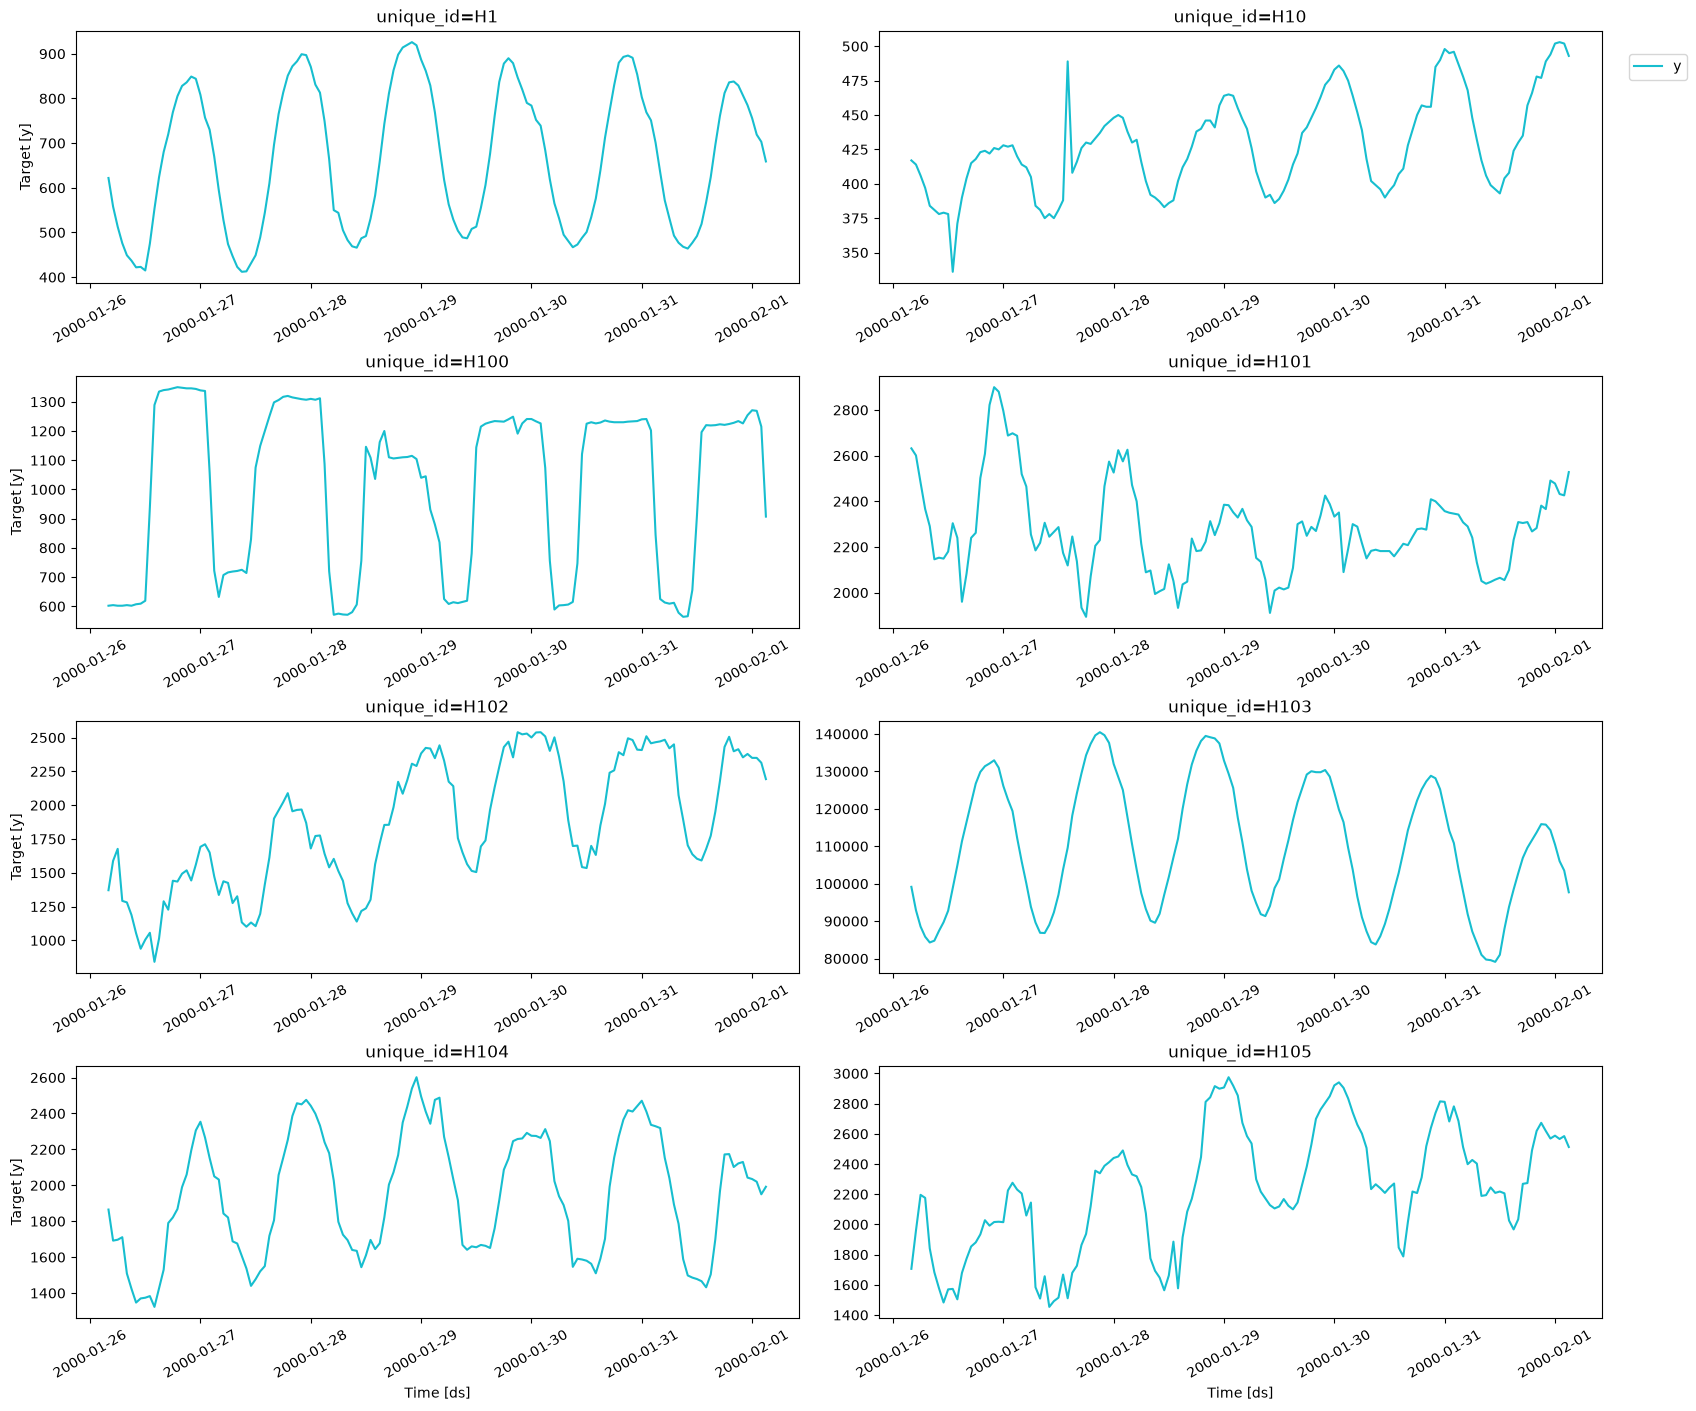

In [4]:
TimeCopilotForecaster.plot(df, max_insample_length=48 * 3, plot_random=False)

## Import the models

In [5]:
from timecopilot.models.foundation import CIProto

## Create a TimeCopilotForecaster

In [6]:
models = [
    CIProto(alias="CIProto", context_length=512),
]

tcf = TimeCopilotForecaster(models=models)

## Generate forecast

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly)
- h: The forecast horizon, which is the number of periods to predict
- seasonality: The seasonal period of your data, which can be inferred if not provided
- level / quantiles: native prediction intervals or quantile forecasts

ci-proto's native quantile grid is 0.1 to 0.9, so the widest native interval is the 80% one.

In [7]:
h = 48
level = [80]
fcst_df = tcf.forecast(df=df, h=h, level=level)
fcst_df.head()

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Fetching 3 files: 100%|██████████| 3/3 [00:00<00:00, 570.65it/s]

2026-11-16 23:13:17  [TileLang:tilelang.jit.kernel:INFO]: TileLang begins to compile kernel `mamba_mimo_fwd_kernel` with `out_idx=[]`


2026-11-16 23:13:36  [TileLang:tilelang.jit.kernel:INFO]: TileLang completes to compile kernel `mamba_mimo_fwd_kernel`


/usr/local/lib/python3.12/site-packages/torch/nn/functional.py:2954: UserWarning: Mismatch dtype between input and weight: input dtype = c10::BFloat16, weight dtype = float, Cannot dispatch to fused implementation. (Triggered internally at /pytorch/aten/src/ATen/native/layer_norm.cpp:344.)
  return torch.rms_norm(input, normalized_shape, weight, eps)


,unique_id,ds,CIProto,CIProto-lo-80,CIProto-hi-80
0,H1,2000-02-01 04:00:00,606.0,596.0,617.0
1,H1,2000-02-01 05:00:00,550.0,535.0,565.0
2,H1,2000-02-01 06:00:00,510.0,493.0,527.0
3,H1,2000-02-01 07:00:00,476.0,456.0,495.0
4,H1,2000-02-01 08:00:00,453.0,432.0,476.0


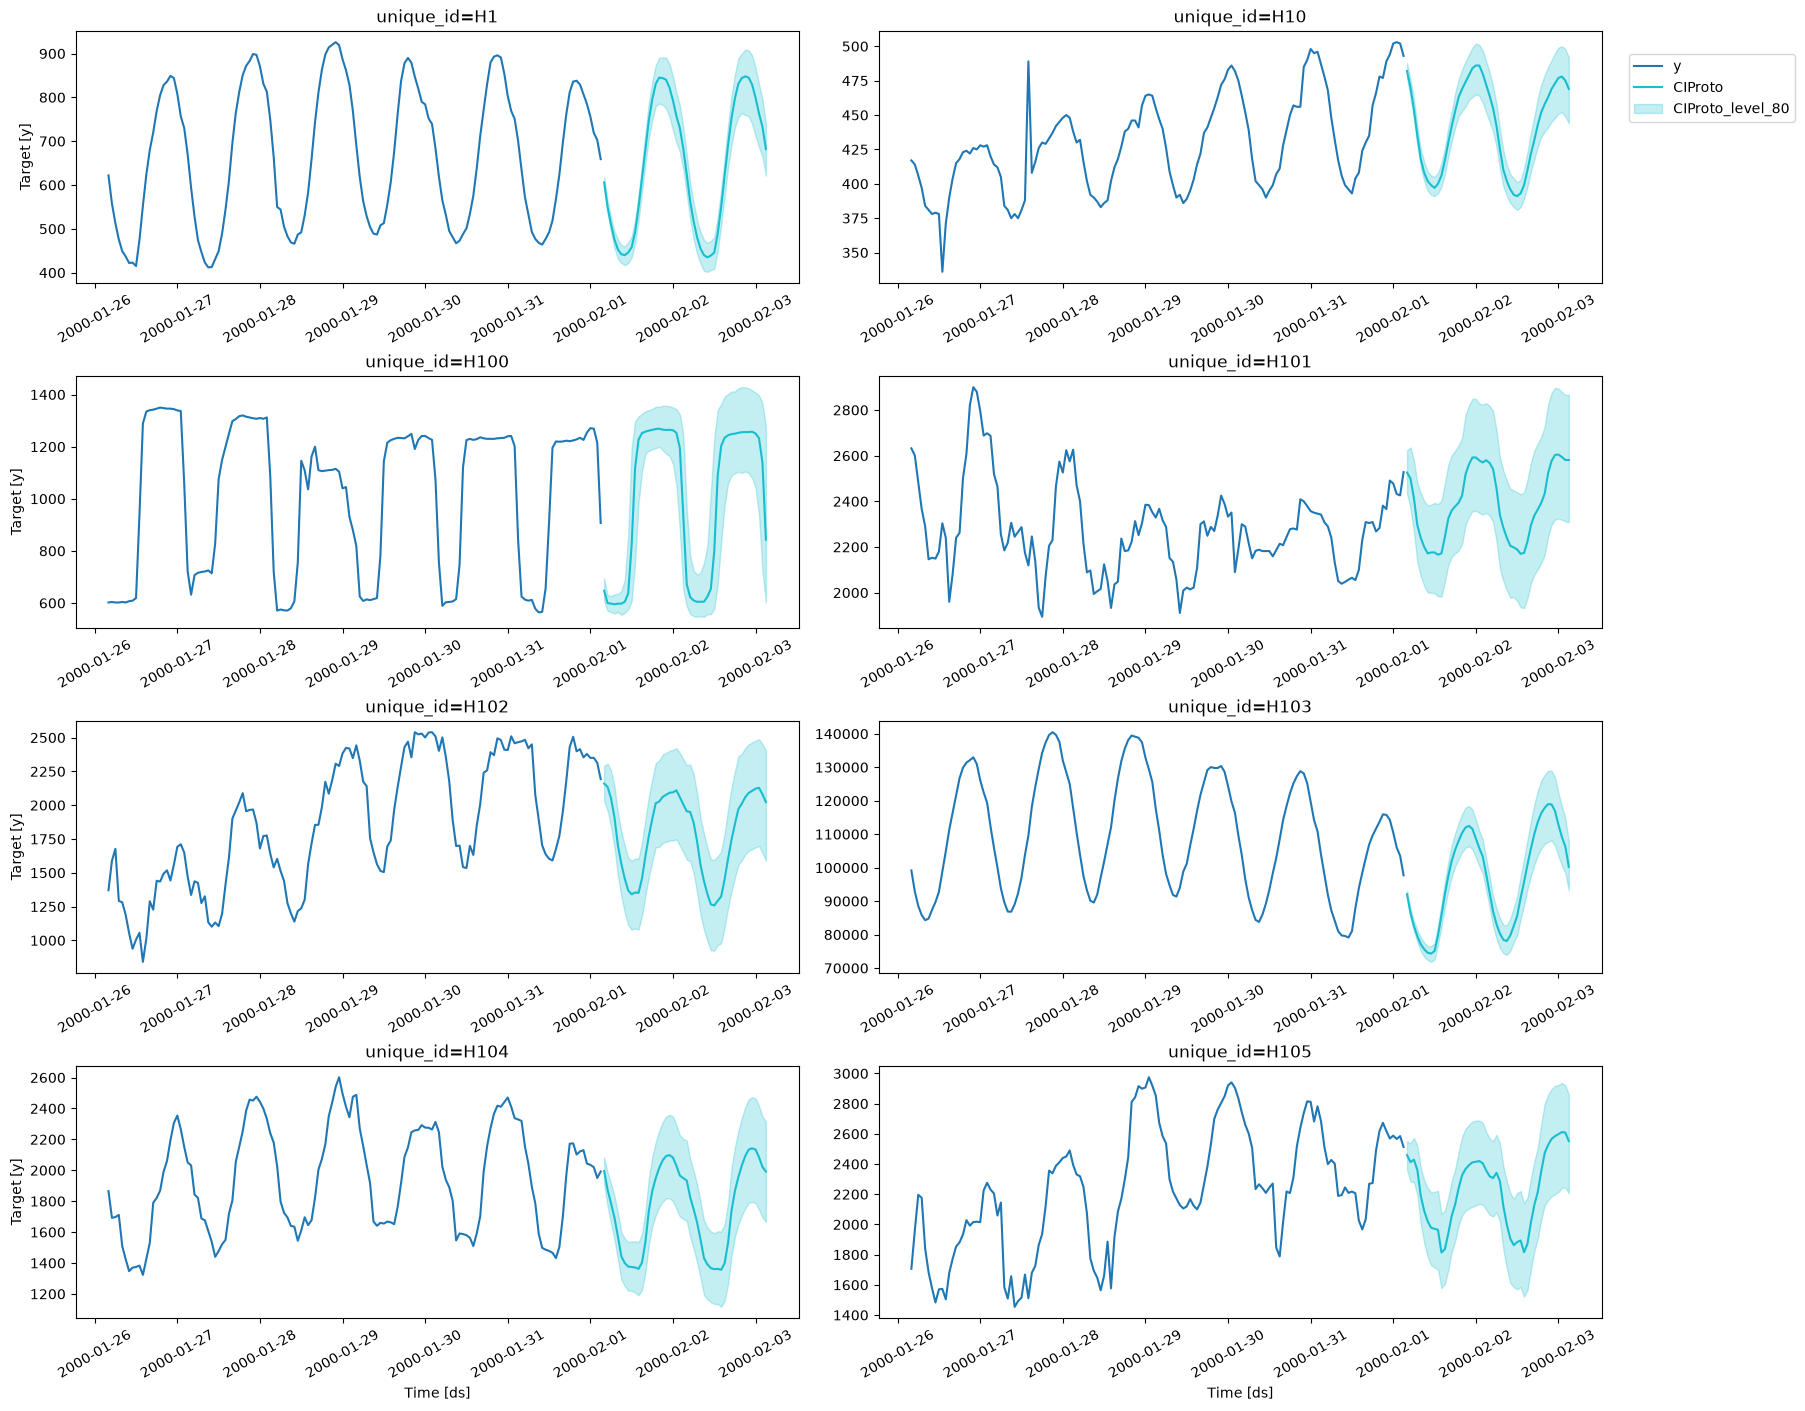

In [8]:
tcf.plot(df, fcst_df, level=level, max_insample_length=48 * 3, plot_random=False)

## Wider intervals with conformal prediction

Levels beyond 80% fall outside the native grid, so a `level=[95]` request would just repeat the 0.1 and 0.9 bounds. For 95% intervals, pass `prediction_intervals=ConformalIntervals(...)`: the intervals are then calibrated from the cross-validation errors of ci-proto's own point forecast and replace the native quantiles. See [Conformal prediction](https://docs.timecopilot.dev/foundationforecast/conformal-prediction/) for the details.

In [9]:
tcf_conformal = TimeCopilotForecaster(
    models=[
        CIProto(
            alias="CIProto-CF",
            context_length=512,
            prediction_intervals=ConformalIntervals(n_windows=10),
        )
    ]
)

level_cf = [80, 95]
fcst_cf_df = tcf_conformal.forecast(df=df, h=h, level=level_cf)
fcst_cf_df.head()

0it [00:00, ?it/s]

2it [00:00, 13.45it/s]

4it [00:00, 12.92it/s]

6it [00:00, 12.65it/s]

8it [00:00, 12.47it/s]

10it [00:00, 12.45it/s]

10it [00:00, 12.56it/s]

,unique_id,ds,CIProto-CF,CIProto-CF-lo-95,CIProto-CF-lo-80,CIProto-CF-hi-80,CIProto-CF-hi-95
0,H1,2000-02-01 04:00:00,606.0,595.425,597.0,615.0,616.575
1,H1,2000-02-01 05:00:00,550.0,516.475,540.7,559.3,583.525
2,H1,2000-02-01 06:00:00,510.0,499.475,501.8,518.2,520.525
3,H1,2000-02-01 07:00:00,476.0,465.475,466.0,486.0,486.525
4,H1,2000-02-01 08:00:00,453.0,444.850,449.8,456.2,461.150


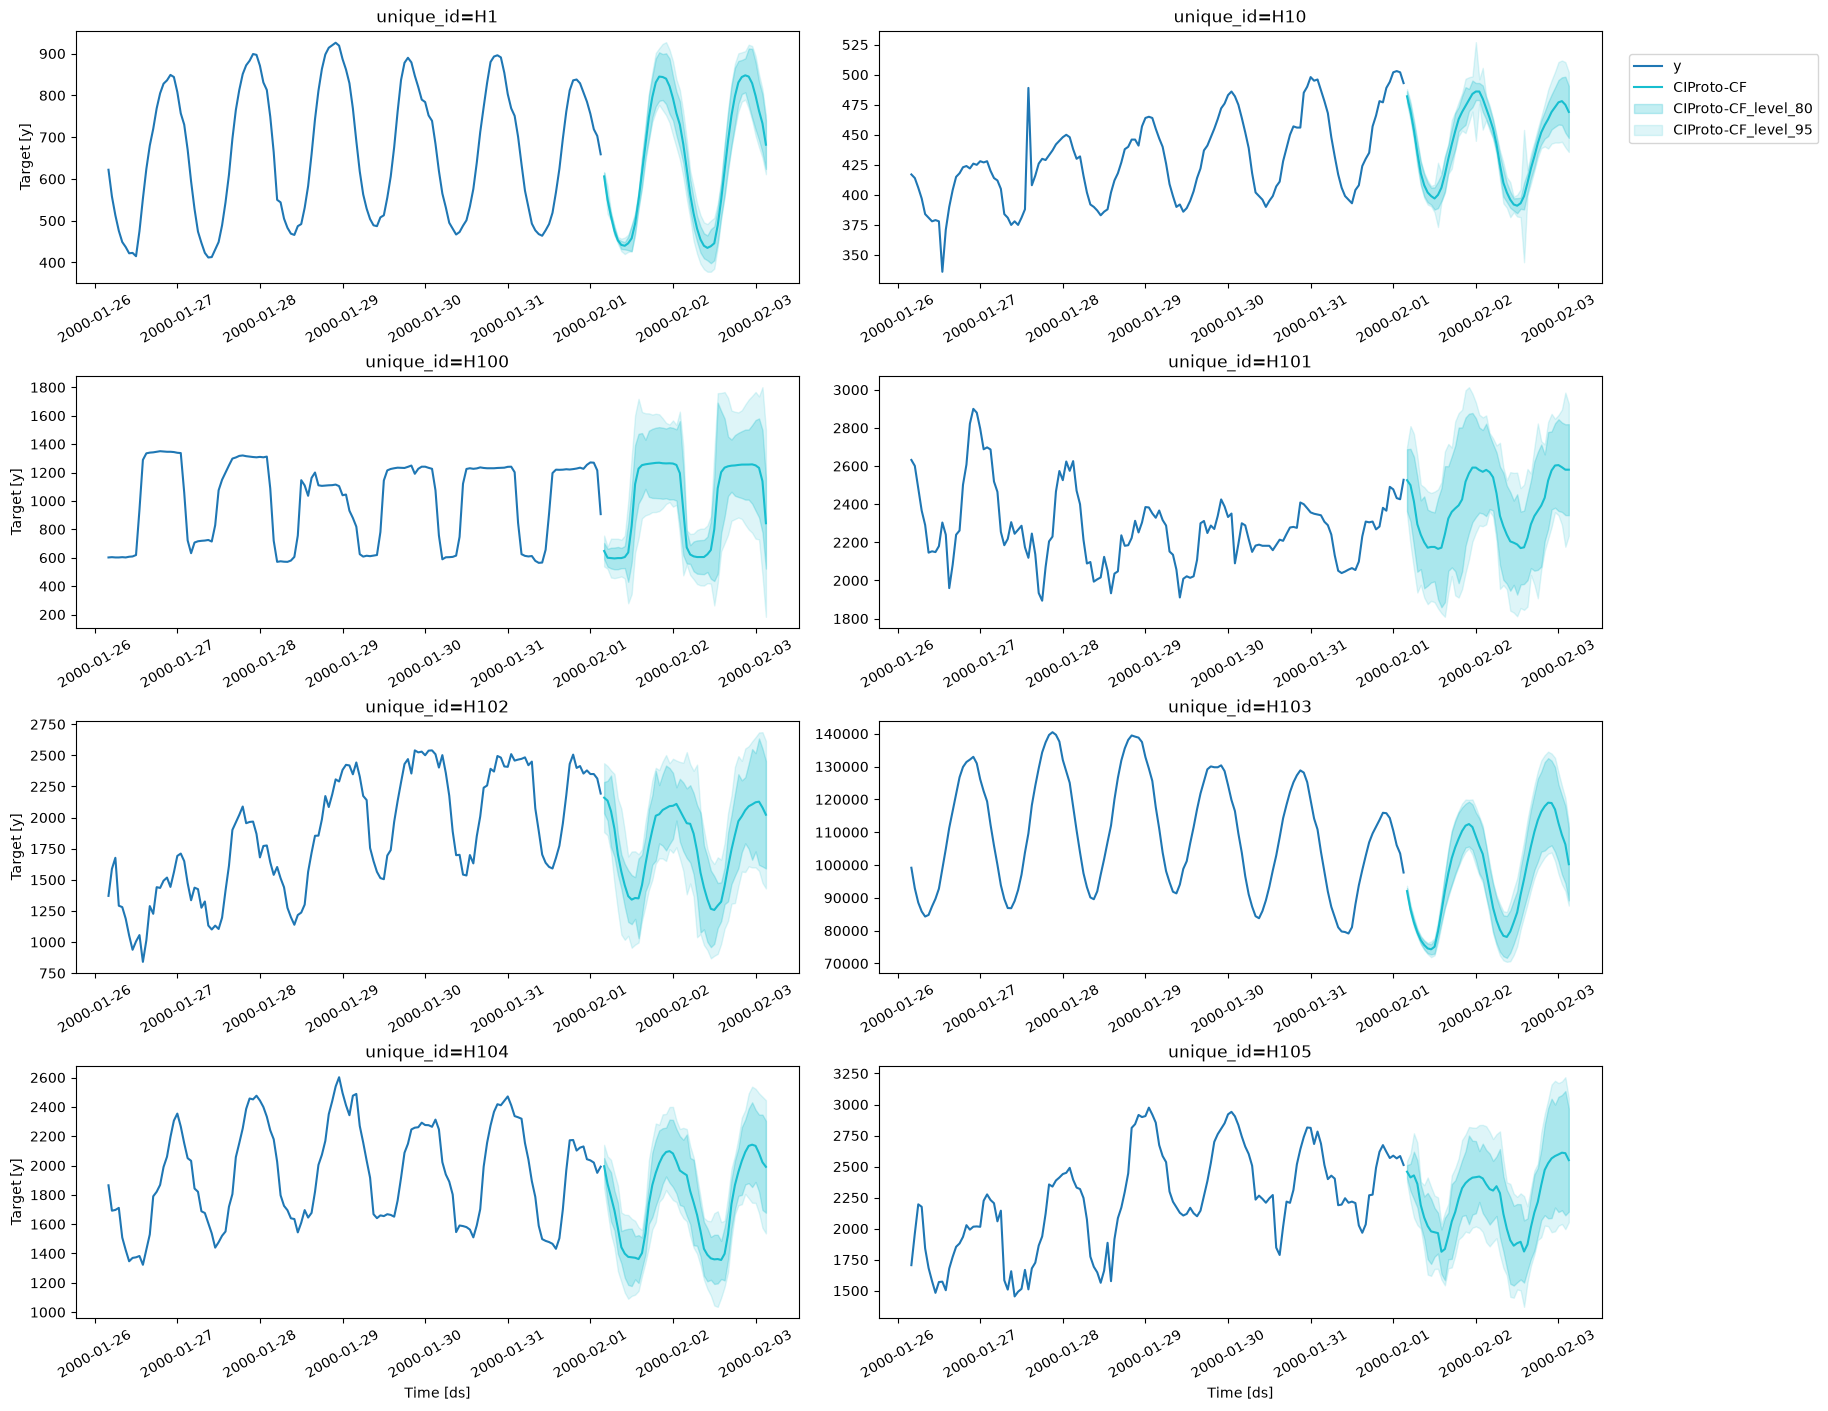

In [10]:
tcf_conformal.plot(
    df,
    fcst_cf_df,
    level=level_cf,
    max_insample_length=48 * 3,
    plot_random=False,
)

## Cross validation

`cross_validation()` returns the median and the interval bands at every cutoff. The conformal intervals are recalibrated at every cutoff using only data before it.

In [11]:
cv_df = tcf.cross_validation(df=df, h=h, n_windows=2, level=level)
cv_cf_df = tcf_conformal.cross_validation(
    df=df, h=h, n_windows=2, level=level_cf
)
cv_cf_df.head()

0it [00:00, ?it/s]

2it [00:00, 11.50it/s]

2it [00:00, 11.41it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

1it [00:00,  2.46it/s]

... (12 outputs left out)

10it [00:00, 12.47it/s]


2it [00:02,  1.04s/it]

2it [00:02,  1.07s/it]

,unique_id,ds,cutoff,y,CIProto-CF,CIProto-CF-lo-95,CIProto-CF-lo-80,CIProto-CF-hi-80,CIProto-CF-hi-95
0,H1,2000-01-28 04:00:00,2000-01-28 03:00:00,664.0,676.0,667.000,669.7,682.3,685.000
1,H1,2000-01-28 05:00:00,2000-01-28 03:00:00,550.0,603.0,590.475,593.7,612.3,615.525
2,H1,2000-01-28 06:00:00,2000-01-28 03:00:00,544.0,555.0,541.425,544.8,565.2,568.575
3,H1,2000-01-28 07:00:00,2000-01-28 03:00:00,505.0,515.0,502.425,504.9,525.1,527.575
4,H1,2000-01-28 08:00:00,2000-01-28 03:00:00,483.0,485.0,475.425,479.7,490.3,494.575


## Evaluation

In [12]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import coverage, mase, scaled_crps

In [13]:
def evaluate_cv(cv, levels):
    eval_df = evaluate(
        cv.drop(columns=["cutoff"]),
        train_df=df,
        metrics=[partial(mase, seasonality=24), scaled_crps, coverage],
        level=levels,
    )
    return eval_df.groupby("metric").mean(numeric_only=True).T


pd.concat([evaluate_cv(cv_df, level), evaluate_cv(cv_cf_df, level_cf)]).round(3)

metric,coverage_level80,mase,scaled_crps,coverage_level95
CIProto,0.863,0.698,0.030,NaN
CIProto-CF,0.839,0.698,0.021,0.935
